# ECG Pre-processing: Verification

In this notebook, the ECG pre-processing of `ECG-processing.ipynb` is checked with four simple tests:

1. **Data type:** the signals are in double format (`float64`).
2. **Expected results:** a test signal with known content is cleaned, and the result is compared
   with the known clean signal.
3. **Overall functionality:** the saved result of the real recording is checked.
4. **Computational time:** the time needed by both methods is measured.

Every check gives **PASS** or **FAIL**.

## 1. Libraries and data

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import h5py
from scipy.io import loadmat
from scipy.ndimage import median_filter
from scipy.ndimage import uniform_filter1d
from scipy.signal import find_peaks

plt.rcParams["axes.grid"] = True

file = h5py.File("ecgConditioningExample.mat", "r")
ecg = file["ecg"][:]                          # original signal
fs = file["fs"][0][0]                         # sampling frequency
file.close()

saved = loadmat("ecgConditioningExample-processed.mat")

all_checks = []                               # all checks of all tests

## 2. Test 1: Data type

The original signal, the sampling frequency and the saved results are expected in
**double format** (`float64`). The saved signals must also have the correct size
(30 000 samples x 6 channels) and must not contain invalid values (NaN).

In [2]:
checks = []
checks.append(["original ecg is double", ecg.dtype == np.float64])
checks.append(["fs is double", type(fs) == np.float64])
checks.append(["Method A result is double",
               saved["ecg_method_a"].dtype == np.float64])
checks.append(["Method B result is double",
               saved["ecg_method_b"].dtype == np.float64])
checks.append(["Method A result has size 30000 x 6",
               saved["ecg_method_a"].shape == (30000, 6)])
checks.append(["Method B result has size 30000 x 6",
               saved["ecg_method_b"].shape == (30000, 6)])
checks.append(["no NaN in Method A result",
               not np.isnan(saved["ecg_method_a"]).any()])
checks.append(["no NaN in Method B result",
               not np.isnan(saved["ecg_method_b"]).any()])

for c in checks:
    print("PASS" if c[1] else "FAIL", " ", c[0])
all_checks = all_checks + checks

PASS   original ecg is double
PASS   fs is double
PASS   Method A result is double
PASS   Method B result is double
PASS   Method A result has size 30000 x 6
PASS   Method B result has size 30000 x 6
PASS   no NaN in Method A result
PASS   no NaN in Method B result


## 3. Test 2: Expected results with a test signal

A test signal is made, so that the correct result is known:

* **clean ECG:** 30 beats, one beat every second (60 beats per minute), each beat with an R wave and a T wave
* **added problems:** an offset of 40 000, a slow baseline wander (0.2 Hz), power-line noise (50 Hz)
  and one spike of 130 000 000 at sample 10 000

After cleaning, the spike must be found at sample 10 000, the offset must be removed,
the shape must be almost the same as the clean ECG, and all 30 beats must be found.

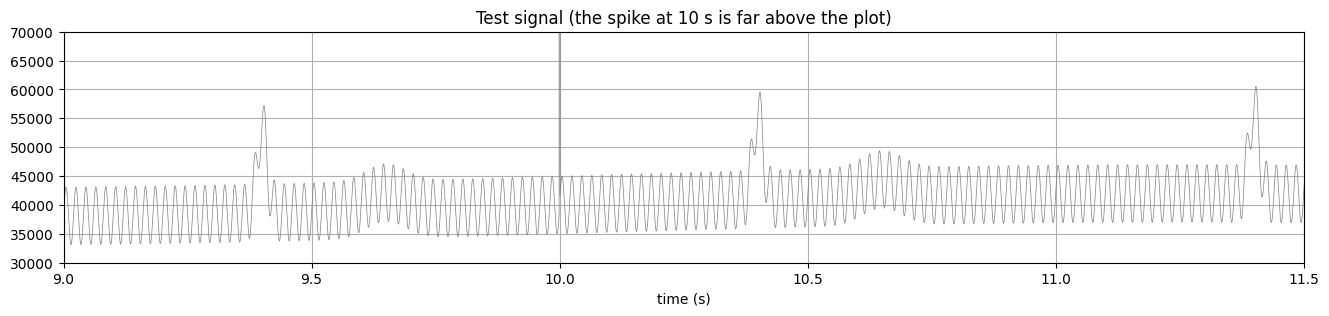

In [3]:
# 30 s, as the real recording
t = np.arange(30000) / fs

clean = np.zeros(30000)
for beat in range(30):
    bt = 0.4 + beat                           # time of the beat
    clean = clean + 15000 * np.exp(-0.5 * ((t - bt) / 0.010) ** 2)
    clean = clean + 3000 * np.exp(-0.5 * ((t - bt - 0.25) / 0.040) ** 2)

x = clean + 40000                             # offset
x = x + 2000 * np.sin(2 * np.pi * 0.2 * t)    # baseline wander
x = x + 5000 * np.sin(2 * np.pi * 50 * t)     # power-line noise
x[10000] = 1.3e8                              # spike

plt.figure(figsize=(16, 3))
plt.plot(t, x, linewidth=0.5, color="grey")
plt.ylim(30000, 70000)
plt.xlim(9, 11.5)
plt.title("Test signal (the spike at 10 s is far above the plot)")
plt.xlabel("time (s)")
plt.show()

The test signal is cleaned with exactly the same steps as in `ECG-processing.ipynb`.
The time of both methods is also measured here (for Test 4).

In [4]:
# step 1: spike removal (the same for both methods)
low = np.percentile(x, 1)
high = np.percentile(x, 99)
width = high - low
is_spike = (x > high + 5 * width) | (x < low - 5 * width)
good = ~is_spike
x1 = x.copy()
x1[is_spike] = np.interp(t[is_spike], t[good], x[good])

# Method A: padding, steps 2 to 4 in the frequency domain
start = time.perf_counter()
xa = np.concatenate([x1[:1000], x1, x1[-1000:]])
freqs = np.fft.rfftfreq(len(xa), 1 / fs)
X = np.fft.rfft(xa)
X[freqs > 100] = 0                            # step 2: low-pass
for h in range(50, 500, 50):
    X[np.abs(freqs - h) <= 1] = 0             # step 3: power-line
# step 4: offset and baseline
X[freqs < 0.5] = 0
result_a = np.fft.irfft(X, len(xa))[1000:-1000]
time_a = time.perf_counter() - start

# Method B: padding, steps 2 to 4 in the time domain
start = time.perf_counter()
xb = np.concatenate([x1[:300], x1, x1[-300:]])
xb = uniform_filter1d(xb, 5)                  # step 2: low-pass
xb = uniform_filter1d(xb, 20)                 # step 3: power-line
xb = xb - np.mean(xb)                         # step 4: offset
baseline = median_filter(median_filter(xb, 201), 601)
result_b = (xb - baseline)[300:-300]          # step 4: baseline wander
time_b = time.perf_counter() - start

In [5]:
reference = clean - np.mean(clean)            # clean ECG without offset

checks = []
checks.append(["spike found at sample 10000",
               list(np.where(is_spike)[0]) == [10000]])

for name, result in [["Method A", result_a], ["Method B", result_b]]:
    similarity = np.corrcoef(result, reference)[0, 1]
    beats, _ = find_peaks(result, height=0.5 * np.max(result),
                          distance=300)
    checks.append([name + ": offset removed (mean below 1000)",
                   abs(np.mean(result)) < 1000])
    checks.append([name + ": shape almost the same as the clean ECG",
                   similarity > 0.98])
    checks.append([name + ": all 30 beats found", len(beats) == 30])
    print(name, " mean:", round(np.mean(result)),
          "  similarity:", round(similarity, 3), "  beats:", len(beats))

print()
for c in checks:
    print("PASS" if c[1] else "FAIL", " ", c[0])
all_checks = all_checks + checks

Method A  mean: 0   similarity: 0.997   beats: 30
Method B  mean: 548   similarity: 0.991   beats: 30

PASS   spike found at sample 10000
PASS   Method A: offset removed (mean below 1000)
PASS   Method A: shape almost the same as the clean ECG
PASS   Method A: all 30 beats found
PASS   Method B: offset removed (mean below 1000)
PASS   Method B: shape almost the same as the clean ECG
PASS   Method B: all 30 beats found


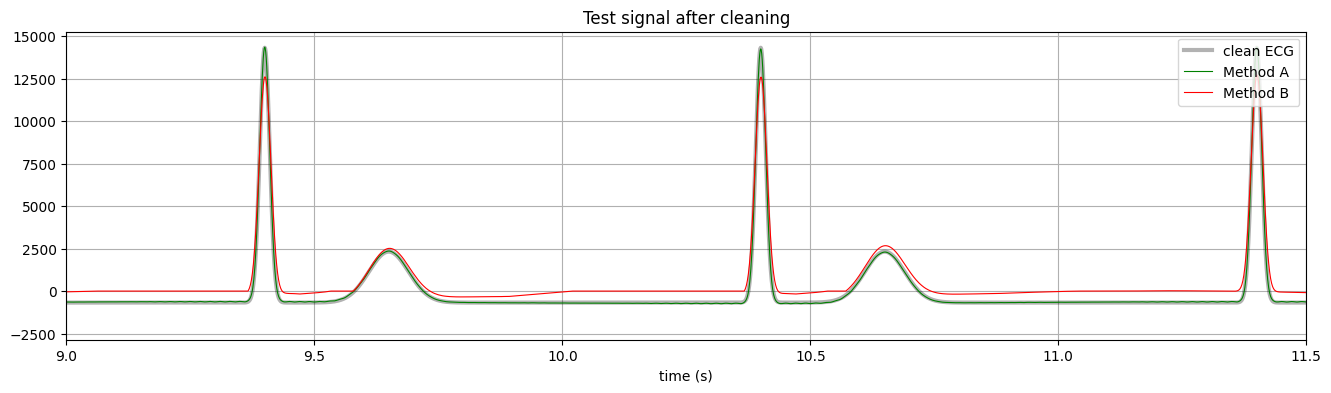

In [6]:
plt.figure(figsize=(16, 4))
plt.plot(t, reference, linewidth=3, color="black", alpha=0.3,
         label="clean ECG")
plt.plot(t, result_a, linewidth=0.8, color="green", label="Method A")
plt.plot(t, result_b, linewidth=0.8, color="red", label="Method B")
plt.xlim(9, 11.5)
plt.title("Test signal after cleaning")
plt.xlabel("time (s)")
plt.legend(loc="upper right")
plt.show()

Both results lie on the clean ECG. In Method B the R-peak is a little lower, because of the
moving averages.

## 4. Test 3: Overall functionality

The saved result of the real recording (`ecgConditioningExample-processed.mat`) is checked:

* Ch4 (not connected) contains only zeros
* no spike is left (all values far below 130 000 000)
* in every connected channel, 30 beats at about 60 beats per minute are found with both methods

In [7]:
# 30000 x 6, one column per channel
result_a = saved["ecg_method_a"]
result_b = saved["ecg_method_b"]

checks = []
checks.append(["Ch4 is only zeros (Method A)",
               np.all(result_a[:, 3] == 0)])
checks.append(["Ch4 is only zeros (Method B)",
               np.all(result_b[:, 3] == 0)])
checks.append(["no spike left (Method A)",
               np.max(np.abs(result_a)) < 1e6])
checks.append(["no spike left (Method B)",
               np.max(np.abs(result_b)) < 1e6])

for name, result in [["A", result_a], ["B", result_b]]:
    for i in [0, 1, 2, 4, 5]:                 # all channels except Ch4
        y = result[:, i]
        if abs(np.min(y)) > np.max(y):        # QRS points down
            y = -y
        beats, _ = find_peaks(y, height=0.5 * np.max(y), distance=300)
        rate = 60 / np.mean(np.diff(beats) / fs)
        print("Ch" + str(i + 1), "Method", name, " beats:", len(beats),
              "  heart rate:", round(rate, 1))
        checks.append(["Ch" + str(i + 1) + " Method " + name
                       + ": 30 beats at about 60 per minute",
                       len(beats) == 30 and abs(rate - 60) < 2])

print()
for c in checks:
    print("PASS" if c[1] else "FAIL", " ", c[0])
all_checks = all_checks + checks

Ch1 Method A  beats: 30   heart rate: 60.4
Ch2 Method A  beats: 30   heart rate: 60.4
Ch3 Method A  beats: 30   heart rate: 60.4
Ch5 Method A  beats: 30   heart rate: 60.4
Ch6 Method A  beats: 30   heart rate: 60.4
Ch1 Method B  beats: 30   heart rate: 60.4
Ch2 Method B  beats: 30   heart rate: 60.4
Ch3 Method B  beats: 30   heart rate: 60.4
Ch5 Method B  beats: 30   heart rate: 60.4
Ch6 Method B  beats: 30   heart rate: 60.4

PASS   Ch4 is only zeros (Method A)
PASS   Ch4 is only zeros (Method B)
PASS   no spike left (Method A)
PASS   no spike left (Method B)
PASS   Ch1 Method A: 30 beats at about 60 per minute
PASS   Ch2 Method A: 30 beats at about 60 per minute
PASS   Ch3 Method A: 30 beats at about 60 per minute
PASS   Ch5 Method A: 30 beats at about 60 per minute
PASS   Ch6 Method A: 30 beats at about 60 per minute
PASS   Ch1 Method B: 30 beats at about 60 per minute
PASS   Ch2 Method B: 30 beats at about 60 per minute
PASS   Ch3 Method B: 30 beats at about 60 per minute
PASS   Ch

## 5. Test 4: Computational time

The time of both methods was measured in Test 2, for a signal of 30 s (one channel).
Both methods must be faster than the signal itself (30 s).

In [8]:
print("Method A:", round(time_a * 1000, 1), "ms")
print("Method B:", round(time_b * 1000, 1), "ms")
print("signal  :", 30, "s")

checks = []
checks.append(["Method A faster than 30 s", time_a < 30])
checks.append(["Method B faster than 30 s", time_b < 30])

print()
for c in checks:
    print("PASS" if c[1] else "FAIL", " ", c[0])
all_checks = all_checks + checks

Method A: 2.2 ms
Method B: 1433.4 ms
signal  : 30 s

PASS   Method A faster than 30 s
PASS   Method B faster than 30 s


Method A is much faster than Method B. Method B needs more time because of the median filters
in step 4. Both methods are much faster than the signal itself.

## 6. Summary

In [9]:
n_pass = 0
for c in all_checks:
    if c[1]:
        n_pass = n_pass + 1

print(n_pass, "of", len(all_checks), "checks passed")
if n_pass == len(all_checks):
    print("The pre-processing is verified.")

31 of 31 checks passed
The pre-processing is verified.
